In [1]:
%pip install yfinance pandas

In [2]:
import pandas as pd
import yfinance as yf

ticker = "RELIANCE.NS"

data = yf.download(
    ticker,
    start="2016-01-01",
    end="2025-01-01",  # end date is exclusive
    interval="1d",
    auto_adjust=True,
    actions=True,
    progress=False,
    multi_level_index=False
)

if data.empty:
    raise RuntimeError("No data downloaded. Try again later or use the NSE archive.")

# Handle yfinance versions that return multi-level columns
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

required_columns = ["Open", "High", "Low", "Close", "Volume"]
missing_columns = [c for c in required_columns if c not in data.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

print("Rows and columns:", data.shape)
print("Date range:", data.index.min().date(), "to", data.index.max().date())
print("Columns:", list(data.columns))
print("\nMissing values:\n", data[required_columns].isna().sum())
print("Duplicate dates:", data.index.duplicated().sum())
print("Non-positive prices:",
      (data[["Open", "High", "Low", "Close"]] <= 0).sum().to_dict())
print("Zero-volume days:", (data["Volume"] == 0).sum())
print("\nFirst five rows:\n", data[required_columns].head())

Rows and columns: (2221, 7)
Date range: 2016-01-01 to 2024-12-31
Columns: ['Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']

Missing values:
 Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate dates: 0
Non-positive prices: {'Open': 0, 'High': 0, 'Low': 0, 'Close': 0}
Zero-volume days: 0

First five rows:
                   Open        High         Low       Close    Volume
Date                                                                
2016-01-01  217.800397  219.763147  217.455308  218.997467   5416562
2016-01-04  216.765117  218.663164  212.818048  214.672958  30170947
2016-01-05  215.751391  217.843550  215.039631  216.797470  14946239
2016-01-06  217.325876  223.969037  215.772933  222.631775  26759864
2016-01-07  220.226861  221.725884  217.422942  218.544510  19739943


In [3]:
development = data.loc["2016-01-01":"2022-12-31"]
validation = data.loc["2023-01-01":"2023-12-31"]
final_test = data.loc["2024-01-01":"2024-12-31"]

print("Development rows:", len(development))
print("Validation rows:", len(validation))
print("Final test rows:", len(final_test))

Development rows: 1730
Validation rows: 245
Final test rows: 246


Daily return summary:
count    1974.0000
mean        0.0011
std         0.0178
min        -0.1315
25%        -0.0085
50%         0.0009
75%         0.0101
max         0.1472
Name: Daily Return, dtype: float64

Five largest daily moves:
            Absolute return  Signed return
Date                                      
2020-03-25           0.1472         0.1472
2020-03-23           0.1315        -0.1315
2020-03-09           0.1234        -0.1234
2020-04-07           0.1194         0.1194
2017-02-22           0.1096         0.1096


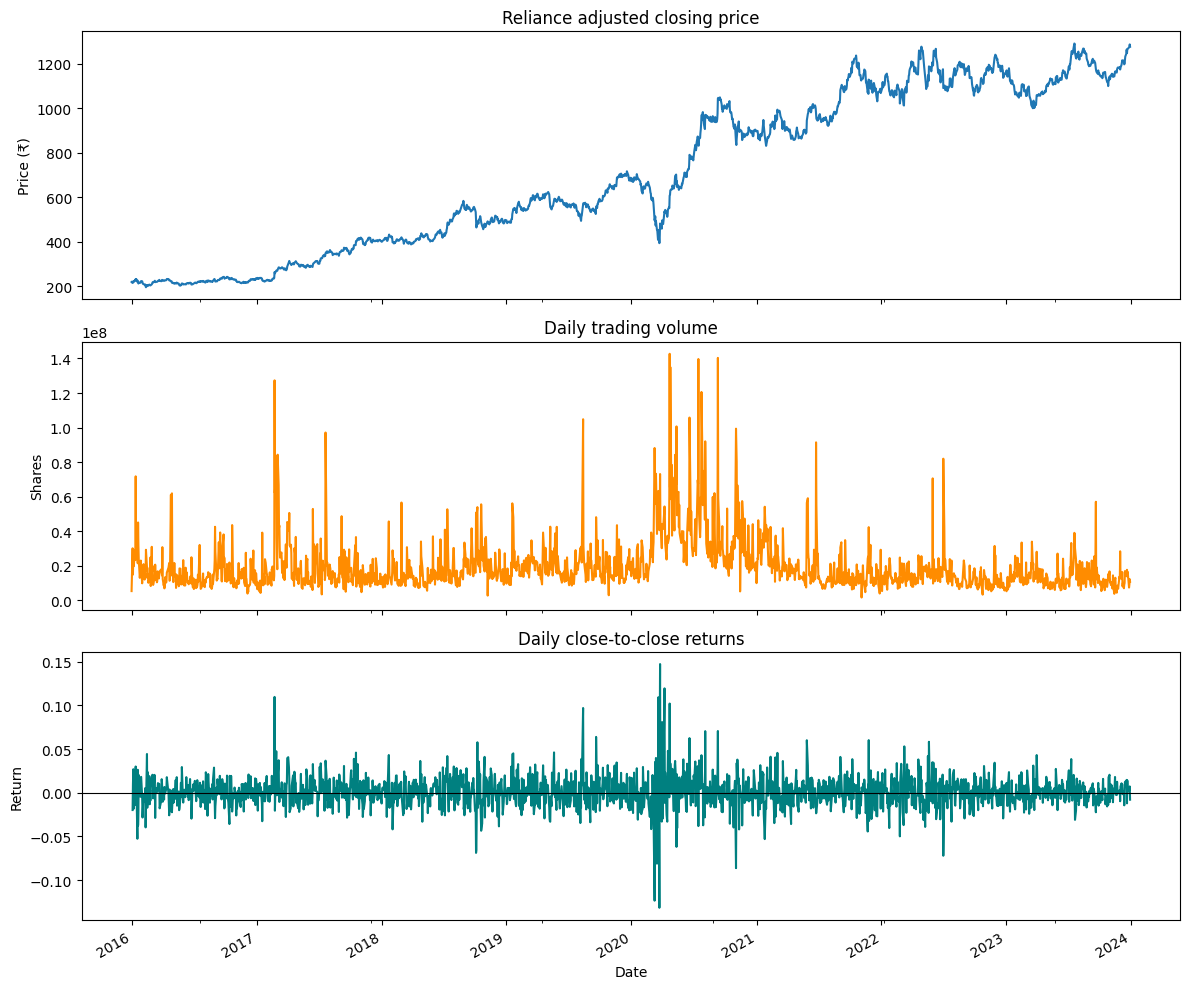

In [4]:
import matplotlib.pyplot as plt

# Use development + validation data only; keep 2024 reserved
analysis = data.loc[:"2023-12-31"].copy()
analysis["Daily Return"] = analysis["Close"].pct_change()

print("Daily return summary:")
print(analysis["Daily Return"].describe().round(4))

print("\nFive largest daily moves:")
print(
    analysis["Daily Return"]
    .abs()
    .nlargest(5)
    .rename("Absolute return")
    .to_frame()
    .join(analysis["Daily Return"].rename("Signed return"))
    .round(4)
)

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

analysis["Close"].plot(ax=axes[0], title="Reliance adjusted closing price")
axes[0].set_ylabel("Price (₹)")

analysis["Volume"].plot(ax=axes[1], color="darkorange",
                        title="Daily trading volume")
axes[1].set_ylabel("Shares")

analysis["Daily Return"].plot(ax=axes[2], color="teal",
                              title="Daily close-to-close returns")
axes[2].set_ylabel("Return")
axes[2].axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

In [5]:
extreme_dates = analysis["Daily Return"].abs().nlargest(5).index

columns_to_show = [
    "Open", "High", "Low", "Close", "Volume",
    "Dividends", "Stock Splits"
]

for date in extreme_dates:
    start = date - pd.Timedelta(days=3)
    end = date + pd.Timedelta(days=3)

    print(f"\nAround {date.date()}:")
    print(
        data.loc[start:end, columns_to_show]
        .round(2)
        .to_string()
    )


Around 2020-03-25:
              Open    High     Low   Close    Volume  Dividends  Stock Splits
Date                                                                         
2020-03-23  407.98  423.03  389.92  393.66  40670949        0.0           0.0
2020-03-24  414.12  431.94  398.89  420.09  45734887        0.0           0.0
2020-03-25  429.17  512.78  428.93  481.92  73130298        0.0           0.0
2020-03-26  487.95  497.35  464.15  474.77  45744488        0.0           0.0
2020-03-27  487.60  493.07  465.87  474.51  41657940        0.0           0.0

Around 2020-03-23:
              Open    High     Low   Close    Volume  Dividends  Stock Splits
Date                                                                         
2020-03-20  418.35  460.83  414.12  453.29  63360475        0.0           0.0
2020-03-23  407.98  423.03  389.92  393.66  40670949        0.0           0.0
2020-03-24  414.12  431.94  398.89  420.09  45734887        0.0           0.0
2020-03-25  429.17  512.

In [6]:
# Work through validation only; keep the final-test year reserved
signals = data.loc[:"2023-12-31"].copy()

window = 20
signals["Rolling_Mean"] = signals["Close"].rolling(window).mean()
signals["Rolling_Std"] = signals["Close"].rolling(window).std()
signals["Z_Score"] = (
    (signals["Close"] - signals["Rolling_Mean"])
    / signals["Rolling_Std"]
)

# Candidate conditions, detected using today's close
signals["Entry_Candidate"] = signals["Z_Score"] < -2
signals["Exit_Candidate"] = signals["Z_Score"] >= 0

print("Rows with a calculated Z-score:",
      signals["Z_Score"].notna().sum())
print("Entry candidate days:",
      signals["Entry_Candidate"].sum())
print("Exit candidate days:",
      signals["Exit_Candidate"].sum())

print("\nLatest candidate signals:")
print(
    signals.loc[
        signals["Entry_Candidate"] | signals["Exit_Candidate"],
        ["Close", "Z_Score", "Entry_Candidate", "Exit_Candidate"]
    ].tail(10).round(3)
)

Rows with a calculated Z-score: 1956
Entry candidate days: 85
Exit candidate days: 1105

Latest candidate signals:
               Close  Z_Score  Entry_Candidate  Exit_Candidate
Date                                                          
2023-12-15  1232.932    1.965            False            True
2023-12-18  1245.480    2.196            False            True
2023-12-19  1263.809    2.491            False            True
2023-12-20  1248.519    1.640            False            True
2023-12-21  1266.008    1.975            False            True
2023-12-22  1267.243    1.752            False            True
2023-12-26  1273.666    1.719            False            True
2023-12-27  1278.013    1.639            False            True
2023-12-28  1287.252    1.690            False            True
2023-12-29  1277.074    1.279            False            True


In [7]:
from math import floor
import pandas as pd

bt = data.loc[:"2023-12-31"].copy()

window = 20
entry_threshold = -2
exit_threshold = 0

initial_capital = 100_000
allocation_fraction = 0.10
slippage_rate = 0.0005  # example: 0.05% per side
cost_rate = 0.001       # example: 0.10% per side

bt["Z_Score"] = (
    (bt["Close"] - bt["Close"].rolling(window).mean())
    / bt["Close"].rolling(window).std()
)

cash = initial_capital
quantity = 0
pending_order = None
entry = None
trade_log = []

for i in range(window - 1, len(bt)):
    date = bt.index[i]

    # Fill the previous session's signal at today's open
    if pending_order is not None:
        if pending_order["side"] == "BUY":
            entry_fill = bt["Open"].iloc[i] * (1 + slippage_rate)
            quantity = floor(
                cash * allocation_fraction
                / (entry_fill * (1 + cost_rate))
            )

            if quantity > 0:
                entry_value = quantity * entry_fill
                entry_fee = entry_value * cost_rate
                cash -= entry_value + entry_fee

                entry = {
                    "signal_date": pending_order["signal_date"],
                    "fill_date": date,
                    "fill_price": entry_fill,
                    "fee": entry_fee,
                    "quantity": quantity,
                    "fill_index": i,
                }

        elif pending_order["side"] == "SELL" and quantity > 0:
            exit_fill = bt["Open"].iloc[i] * (1 - slippage_rate)
            exit_value = quantity * exit_fill
            exit_fee = exit_value * cost_rate
            cash += exit_value - exit_fee

            net_pnl = (
                exit_value - exit_fee
                - (entry["quantity"] * entry["fill_price"] + entry["fee"])
            )

            trade_log.append({
                "entry_signal_date": entry["signal_date"],
                "entry_fill_date": entry["fill_date"],
                "exit_signal_date": pending_order["signal_date"],
                "exit_fill_date": date,
                "quantity": quantity,
                "entry_fill": round(entry["fill_price"], 2),
                "exit_fill": round(exit_fill, 2),
                "entry_fee": round(entry["fee"], 2),
                "exit_fee": round(exit_fee, 2),
                "net_pnl": net_pnl,
                "holding_sessions": i - entry["fill_index"],
            })

            quantity = 0
            entry = None

        pending_order = None

    # Today's close creates an order for the next session
    z = bt["Z_Score"].iloc[i]

    if pd.notna(z):
        if quantity == 0 and z < entry_threshold:
            pending_order = {"side": "BUY", "signal_date": date}

        elif quantity > 0 and z >= exit_threshold:
            pending_order = {"side": "SELL", "signal_date": date}

trades = pd.DataFrame(trade_log)

print("Completed trades:", len(trades))
print("Ending cash:", round(cash, 2))
print(trades.head())

Completed trades: 30
Ending cash: 103073.12
  entry_signal_date entry_fill_date exit_signal_date exit_fill_date  quantity  \
0        2016-02-11      2016-02-12       2016-02-29     2016-03-01        49   
1        2016-04-28      2016-04-29       2016-05-27     2016-05-30        46   
2        2016-11-02      2016-11-03       2016-12-01     2016-12-02        44   
3        2017-01-18      2017-01-19       2017-02-14     2017-02-15        44   
4        2017-05-05      2017-05-08       2017-05-29     2017-05-30        34   

   entry_fill  exit_fill  entry_fee  exit_fee     net_pnl  holding_sessions  
0      201.53     207.97       9.87     10.19  295.414917                12  
1      216.79     212.86       9.97      9.79 -200.713349                21  
2      223.43     217.11       9.83      9.55 -297.314455                20  
3      225.89     229.54       9.94     10.10  140.290330                18  
4      290.24     295.59       9.87     10.05  162.196716                16  


In [8]:
last_close = bt["Close"].iloc[-1]
marked_equity = cash + quantity * last_close

print("Completed trades:", len(trades))
print("Realized net P&L:", round(trades["net_pnl"].sum(), 2))
print("Ending cash:", round(cash, 2))
print("Shares still held:", quantity)
print("Last close:", round(last_close, 2))
print("Portfolio value at last close:", round(marked_equity, 2))

if quantity > 0:
    open_pnl_before_exit_costs = (
        quantity * last_close
        - (quantity * entry["fill_price"] + entry["fee"])
    )
    print("Open-position P&L before exit costs:",
          round(open_pnl_before_exit_costs, 2))
    print("Open trade details:", entry)

if pending_order is not None:
    print("Unfilled order at end of data:", pending_order)

Completed trades: 30
Realized net P&L: 3073.12
Ending cash: 103073.12
Shares still held: 0
Last close: 1277.07
Portfolio value at last close: 103073.12


In [9]:
import numpy as np
import pandas as pd

# --- Strategy and execution assumptions ---
initial_cash = 100_000
position_fraction = 0.10
entry_threshold = -2.0
exit_threshold = 0.0
slippage_rate = 0.0005       # 0.05% each side
transaction_cost_rate = 0.001  # 0.10% each side

# Work on a sorted copy; dates must be the index.
bt = bt.sort_index().copy()

required_columns = {"Open", "Close"}
missing_columns = required_columns - set(bt.columns)
if missing_columns:
    raise ValueError(f"bt is missing required columns: {missing_columns}")

# Find the Z-score column, including common names like Z_score or rolling_zscore.
def normalize_name(name):
    return "".join(ch for ch in str(name).lower() if ch.isalnum())

z_candidates = [
    col for col in bt.columns
    if normalize_name(col) in {"z", "zscore"}
    or normalize_name(col).endswith("zscore")
]

if not z_candidates:
    raise ValueError(
        "Could not find the Z-score column. Check bt.columns and set z_col "
        "manually to your Z-score column name."
    )

z_col = z_candidates[0]
print("Using Z-score column:", z_col)

# --- Backtest state ---
cash = float(initial_cash)
shares = 0
entry_date = None
entry_fill_price = None
entry_cash_outlay = 0.0

trades = []
equity_records = []

# Record initial capital on the first date.
equity_records.append({
    "Date": bt.index[0],
    "Equity": cash
})

# Signals use the previous day's Z-score.
# Orders execute at today's Open, avoiding same-day lookahead.
for i in range(1, len(bt)):
    previous_z = bt[z_col].iloc[i - 1]
    today_open = bt["Open"].iloc[i]
    today_close = bt["Close"].iloc[i]

    # Exit an open position when the previous day's Z-score reaches 0.
    if shares > 0 and pd.notna(previous_z) and previous_z >= exit_threshold:
        exit_fill_price = today_open * (1 - slippage_rate)
        gross_sale = shares * exit_fill_price
        exit_fee = gross_sale * transaction_cost_rate
        net_sale_proceeds = gross_sale - exit_fee

        cash += net_sale_proceeds
        net_pnl = net_sale_proceeds - entry_cash_outlay

        trades.append({
            "Entry date": entry_date,
            "Exit date": bt.index[i],
            "Shares": shares,
            "Entry fill": entry_fill_price,
            "Exit fill": exit_fill_price,
            "Net P&L": net_pnl
        })

        shares = 0
        entry_date = None
        entry_fill_price = None
        entry_cash_outlay = 0.0

    # Enter when flat and the previous day's Z-score is below -2.
    elif shares == 0 and pd.notna(previous_z) and previous_z < entry_threshold:
        trade_budget = cash * position_fraction
        entry_fill_price = today_open * (1 + slippage_rate)

        # Integer shares; ensure the entry fee also fits within the budget.
        shares_to_buy = int(
            trade_budget
            / (entry_fill_price * (1 + transaction_cost_rate))
        )

        if shares_to_buy > 0:
            gross_purchase = shares_to_buy * entry_fill_price
            entry_fee = gross_purchase * transaction_cost_rate
            entry_cash_outlay = gross_purchase + entry_fee

            cash -= entry_cash_outlay
            shares = shares_to_buy
            entry_date = bt.index[i]

    # Record equity every day, after today's trade decision, marked at today's Close.
    equity_records.append({
        "Date": bt.index[i],
        "Equity": cash + shares * today_close,
        "Cash": cash,
        "Shares": shares
    })

# --- Build equity curve and calculate drawdown ---
equity_curve = pd.DataFrame(equity_records).set_index("Date")
equity_curve["Running peak"] = equity_curve["Equity"].cummax()
equity_curve["Drawdown"] = (
    equity_curve["Equity"] / equity_curve["Running peak"]
) - 1

# --- Matched-period buy-and-hold benchmark ---
start_date = equity_curve.index[0]
end_date = equity_curve.index[-1]

start_close = bt.loc[start_date, "Close"]
end_close = bt.loc[end_date, "Close"]

strategy_return = equity_curve["Equity"].iloc[-1] / initial_cash - 1
buy_hold_return = end_close / start_close - 1
max_drawdown = equity_curve["Drawdown"].min()

print(f"\nPeriod: {start_date.date()} to {end_date.date()}")
print(f"Equity rows: {len(equity_curve)}")
print(f"Distinct equity values: {equity_curve['Equity'].nunique()}")
print(f"Starting equity: ₹{initial_cash:,.2f}")
print(f"Ending equity: ₹{equity_curve['Equity'].iloc[-1]:,.2f}")
print(f"Strategy return: {strategy_return:.2%}")
print(f"Buy-and-hold return: {buy_hold_return:.2%}")
print(f"Maximum drawdown: {max_drawdown:.2%}")
print(f"Completed trades: {len(trades)}")

if trades:
    trades_df = pd.DataFrame(trades)
    print(f"Total realized trade P&L: ₹{trades_df['Net P&L'].sum():,.2f}")
else:
    trades_df = pd.DataFrame()
    print("No completed trades.")

if shares > 0:
    print(f"Open position at end: {shares} shares")
else:
    print("Open position at end: none")

Using Z-score column: Z_Score

Period: 2016-01-01 to 2023-12-29
Equity rows: 1975
Distinct equity values: 406
Starting equity: ₹100,000.00
Ending equity: ₹103,073.12
Strategy return: 3.07%
Buy-and-hold return: 483.15%
Maximum drawdown: -3.32%
Completed trades: 30
Total realized trade P&L: ₹3,073.12
Open position at end: none


In [10]:
years = (
    equity_curve.index[-1] - equity_curve.index[0]
).days / 365.25

strategy_cagr = (
    equity_curve["Equity"].iloc[-1] / initial_cash
) ** (1 / years) - 1

bh_close = bt.loc[equity_curve.index, "Close"]
bh_equity = initial_cash * bh_close / bh_close.iloc[0]
bh_drawdown = (bh_equity / bh_equity.cummax()) - 1
buy_hold_cagr = (
    bh_equity.iloc[-1] / bh_equity.iloc[0]
) ** (1 / years) - 1

market_value = (
    equity_curve["Shares"].fillna(0) * bh_close
)
average_exposure = (
    market_value / equity_curve["Equity"]
).mean()

print(f"Strategy CAGR:       {strategy_cagr:.2%}")
print(f"Buy-and-hold CAGR:   {buy_hold_cagr:.2%}")
print(f"Strategy max DD:     {equity_curve['Drawdown'].min():.2%}")
print(f"Buy-and-hold max DD: {bh_drawdown.min():.2%}")
print(f"Average exposure:    {average_exposure:.2%}")

Strategy CAGR:       0.38%
Buy-and-hold CAGR:   24.69%
Strategy max DD:     -3.32%
Buy-and-hold max DD: -45.09%
Average exposure:    1.81%


In [11]:
pnl = trades_df["Net P&L"]

gross_profit = pnl[pnl > 0].sum()
gross_loss = abs(pnl[pnl < 0].sum())
profit_factor = (
    gross_profit / gross_loss if gross_loss > 0 else float("inf")
)

holding_days = (
    pd.to_datetime(trades_df["Exit date"])
    - pd.to_datetime(trades_df["Entry date"])
).dt.days

print(f"Trades: {len(trades_df)}")
print(f"Win rate: {(pnl > 0).mean():.2%}")
print(f"Average winning trade: ₹{pnl[pnl > 0].mean():,.2f}")
print(f"Average losing trade: ₹{pnl[pnl < 0].mean():,.2f}")
print(f"Profit factor: {profit_factor:.2f}")
print(f"Average holding period: {holding_days.mean():.1f} calendar days")

Trades: 30
Win rate: 73.33%
Average winning trade: ₹283.01
Average losing trade: ₹-394.13
Profit factor: 1.97
Average holding period: 18.4 calendar days


In [12]:
val_equity = equity_curve.loc["2023-01-01":"2023-12-31", "Equity"]
val_close = bt.loc[val_equity.index, "Close"]

val_return = val_equity.iloc[-1] / val_equity.iloc[0] - 1
val_bh_return = val_close.iloc[-1] / val_close.iloc[0] - 1
val_drawdown = (val_equity / val_equity.cummax() - 1).min()

val_trades = trades_df[
    pd.to_datetime(trades_df["Entry date"]).dt.year == 2023
]

print(f"2023 strategy return: {val_return:.2%}")
print(f"2023 buy-and-hold return: {val_bh_return:.2%}")
print(f"2023 strategy max drawdown: {val_drawdown:.2%}")
print(f"Trades entered in 2023: {len(val_trades)}")

2023 strategy return: 0.26%
2023 buy-and-hold return: 9.11%
2023 strategy max drawdown: -0.75%
Trades entered in 2023: 5


In [13]:
[
    (name, obj.shape, list(obj.columns))
    for name, obj in globals().copy().items()
    if isinstance(obj, pd.DataFrame)
]

[('data',
  (2221, 7),
  ['Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']),
 ('development',
  (1730, 7),
  ['Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']),
 ('validation',
  (245, 7),
  ['Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']),
 ('final_test',
  (246, 7),
  ['Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']),
 ('analysis',
  (1975, 8),
  ['Close',
   'Dividends',
   'High',
   'Low',
   'Open',
   'Stock Splits',
   'Volume',
   'Daily Return']),
 ('signals',
  (1975, 12),
  ['Close',
   'Dividends',
   'High',
   'Low',
   'Open',
   'Stock Splits',
   'Volume',
   'Rolling_Mean',
   'Rolling_Std',
   'Z_Score',
   'Entry_Candidate',
   'Exit_Candidate']),
 ('bt',
  (1975, 8),
  ['Close',
   'Dividends',
   'High',
   'Low',
   'Open',
   'Stock Splits',
   'Volume',
   'Z_Score']),
 ('equity_curve',
  (1975, 5),
  ['Equity', 'Cash', 'Shares', 'Running peak', 'Drawdown']),
 ('trades_d

In [14]:
full_data = data.sort_index().copy()

# Calculate each date's Z-score using only its trailing 20 closes.
full_data["Z_Score"] = (
    (full_data["Close"] - full_data["Close"].rolling(20).mean())
    / full_data["Close"].rolling(20).std()
)

# Keep 29 Dec 2023 to supply the prior-session signal for the
# first 2024 trading session.
bt = full_data.loc["2023-12-29":"2024-12-31"].copy()

print("Final-test data:", bt.index[0], "to", bt.index[-1])
print("Rows:", len(bt))

Final-test data: 2023-12-29 00:00:00 to 2024-12-31 00:00:00
Rows: 247


In [15]:
import numpy as np
import pandas as pd

# --- Strategy and execution assumptions ---
initial_cash = 100_000
position_fraction = 0.10
entry_threshold = -2.0
exit_threshold = 0.0
slippage_rate = 0.0005       # 0.05% each side
transaction_cost_rate = 0.001  # 0.10% each side

# Work on a sorted copy; dates must be the index.
bt = bt.sort_index().copy()

required_columns = {"Open", "Close"}
missing_columns = required_columns - set(bt.columns)
if missing_columns:
    raise ValueError(f"bt is missing required columns: {missing_columns}")

# Find the Z-score column, including common names like Z_score or rolling_zscore.
def normalize_name(name):
    return "".join(ch for ch in str(name).lower() if ch.isalnum())

z_candidates = [
    col for col in bt.columns
    if normalize_name(col) in {"z", "zscore"}
    or normalize_name(col).endswith("zscore")
]

if not z_candidates:
    raise ValueError(
        "Could not find the Z-score column. Check bt.columns and set z_col "
        "manually to your Z-score column name."
    )

z_col = z_candidates[0]
print("Using Z-score column:", z_col)

# --- Backtest state ---
cash = float(initial_cash)
shares = 0
entry_date = None
entry_fill_price = None
entry_cash_outlay = 0.0

trades = []
equity_records = []

# Record initial capital on the first date.
equity_records.append({
    "Date": bt.index[0],
    "Equity": cash
})

# Signals use the previous day's Z-score.
# Orders execute at today's Open, avoiding same-day lookahead.
for i in range(1, len(bt)):
    previous_z = bt[z_col].iloc[i - 1]
    today_open = bt["Open"].iloc[i]
    today_close = bt["Close"].iloc[i]

    # Exit an open position when the previous day's Z-score reaches 0.
    if shares > 0 and pd.notna(previous_z) and previous_z >= exit_threshold:
        exit_fill_price = today_open * (1 - slippage_rate)
        gross_sale = shares * exit_fill_price
        exit_fee = gross_sale * transaction_cost_rate
        net_sale_proceeds = gross_sale - exit_fee

        cash += net_sale_proceeds
        net_pnl = net_sale_proceeds - entry_cash_outlay

        trades.append({
            "Entry date": entry_date,
            "Exit date": bt.index[i],
            "Shares": shares,
            "Entry fill": entry_fill_price,
            "Exit fill": exit_fill_price,
            "Net P&L": net_pnl
        })

        shares = 0
        entry_date = None
        entry_fill_price = None
        entry_cash_outlay = 0.0

    # Enter when flat and the previous day's Z-score is below -2.
    elif shares == 0 and pd.notna(previous_z) and previous_z < entry_threshold:
        trade_budget = cash * position_fraction
        entry_fill_price = today_open * (1 + slippage_rate)

        # Integer shares; ensure the entry fee also fits within the budget.
        shares_to_buy = int(
            trade_budget
            / (entry_fill_price * (1 + transaction_cost_rate))
        )

        if shares_to_buy > 0:
            gross_purchase = shares_to_buy * entry_fill_price
            entry_fee = gross_purchase * transaction_cost_rate
            entry_cash_outlay = gross_purchase + entry_fee

            cash -= entry_cash_outlay
            shares = shares_to_buy
            entry_date = bt.index[i]

    # Record equity every day, after today's trade decision, marked at today's Close.
    equity_records.append({
        "Date": bt.index[i],
        "Equity": cash + shares * today_close,
        "Cash": cash,
        "Shares": shares
    })

# --- Build equity curve and calculate drawdown ---
equity_curve = pd.DataFrame(equity_records).set_index("Date")
equity_curve["Running peak"] = equity_curve["Equity"].cummax()
equity_curve["Drawdown"] = (
    equity_curve["Equity"] / equity_curve["Running peak"]
) - 1

# --- Matched-period buy-and-hold benchmark ---
start_date = equity_curve.index[0]
end_date = equity_curve.index[-1]

start_close = bt.loc[start_date, "Close"]
end_close = bt.loc[end_date, "Close"]

strategy_return = equity_curve["Equity"].iloc[-1] / initial_cash - 1
buy_hold_return = end_close / start_close - 1
max_drawdown = equity_curve["Drawdown"].min()

print(f"\nPeriod: {start_date.date()} to {end_date.date()}")
print(f"Equity rows: {len(equity_curve)}")
print(f"Distinct equity values: {equity_curve['Equity'].nunique()}")
print(f"Starting equity: ₹{initial_cash:,.2f}")
print(f"Ending equity: ₹{equity_curve['Equity'].iloc[-1]:,.2f}")
print(f"Strategy return: {strategy_return:.2%}")
print(f"Buy-and-hold return: {buy_hold_return:.2%}")
print(f"Maximum drawdown: {max_drawdown:.2%}")
print(f"Completed trades: {len(trades)}")

if trades:
    trades_df = pd.DataFrame(trades)
    print(f"Total realized trade P&L: ₹{trades_df['Net P&L'].sum():,.2f}")
else:
    trades_df = pd.DataFrame()
    print("No completed trades.")

if shares > 0:
    print(f"Open position at end: {shares} shares")
else:
    print("Open position at end: none")

Using Z-score column: Z_Score

Period: 2023-12-29 to 2024-12-31
Equity rows: 247
Distinct equity values: 67
Starting equity: ₹100,000.00
Ending equity: ₹99,436.11
Strategy return: -0.56%
Buy-and-hold return: -5.64%
Maximum drawdown: -1.31%
Completed trades: 3
Total realized trade P&L: ₹-481.51
Open position at end: 8 shares


In [16]:
last_close = bt["Close"].iloc[-1]

if shares > 0:
    estimated_exit_fill = last_close * (1 - slippage_rate)
    estimated_exit_proceeds = (
        shares
        * estimated_exit_fill
        * (1 - transaction_cost_rate)
    )
    liquidated_final_equity = cash + estimated_exit_proceeds
else:
    liquidated_final_equity = cash

liquidated_return = liquidated_final_equity / initial_cash - 1

print(f"Final marked-to-market equity: ₹{equity_curve['Equity'].iloc[-1]:,.2f}")
print(f"Equity after estimated liquidation: ₹{liquidated_final_equity:,.2f}")
print(f"Return after estimated liquidation: {liquidated_return:.2%}")

Final marked-to-market equity: ₹99,436.11
Equity after estimated liquidation: ₹99,421.66
Return after estimated liquidation: -0.58%


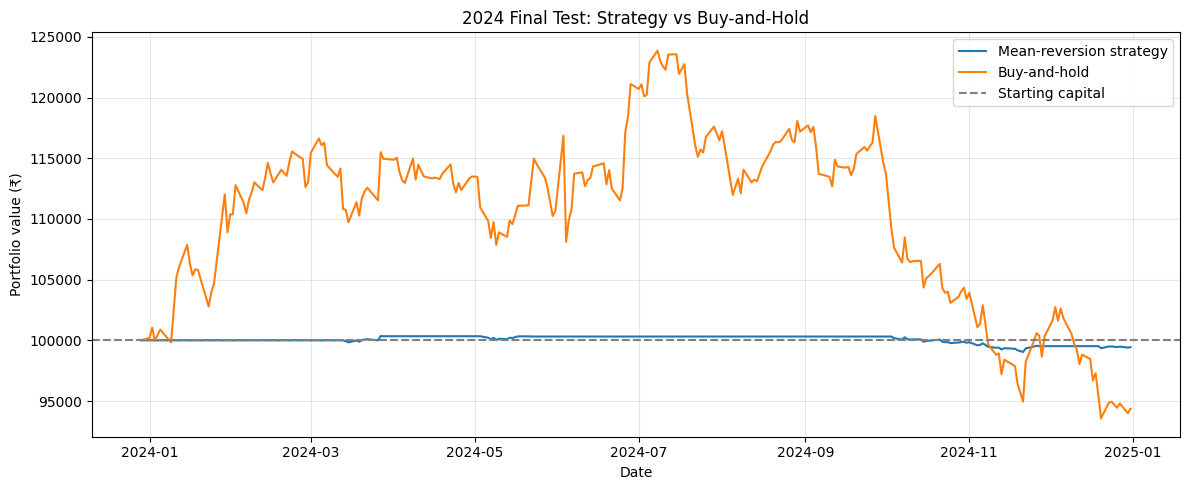

In [17]:
import matplotlib.pyplot as plt

test_close = bt.loc[equity_curve.index, "Close"]
buy_hold_curve = initial_cash * test_close / test_close.iloc[0]

plt.figure(figsize=(12, 5))
plt.plot(equity_curve.index, equity_curve["Equity"], label="Mean-reversion strategy")
plt.plot(buy_hold_curve.index, buy_hold_curve, label="Buy-and-hold")
plt.axhline(initial_cash, color="gray", linestyle="--", label="Starting capital")

plt.title("2024 Final Test: Strategy vs Buy-and-Hold")
plt.xlabel("Date")
plt.ylabel("Portfolio value (₹)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

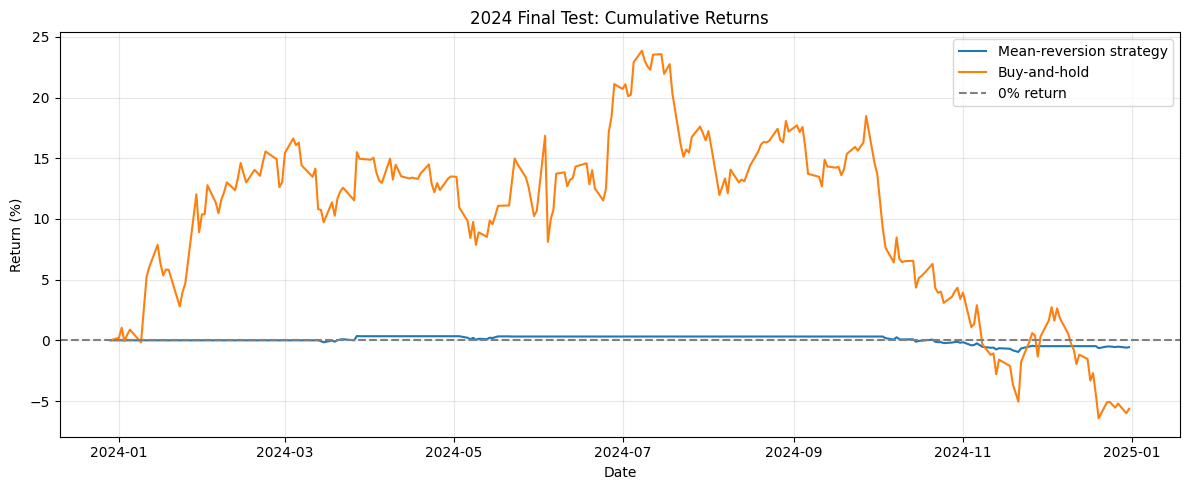

In [18]:
strategy_return_curve = (
    equity_curve["Equity"] / initial_cash - 1
) * 100

buy_hold_return_curve = (
    buy_hold_curve / initial_cash - 1
) * 100

plt.figure(figsize=(12, 5))
plt.plot(
    strategy_return_curve.index,
    strategy_return_curve,
    label="Mean-reversion strategy"
)
plt.plot(
    buy_hold_return_curve.index,
    buy_hold_return_curve,
    label="Buy-and-hold"
)
plt.axhline(0, color="gray", linestyle="--", label="0% return")

plt.title("2024 Final Test: Cumulative Returns")
plt.xlabel("Date")
plt.ylabel("Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2024 Final-Test Interpretation

The mean-reversion strategy ended 2024 with a marked-to-market return of approximately **−0.56%**, compared with **−5.64%** for buy-and-hold. If the remaining position is liquidated using the model’s assumed costs, the strategy return is approximately **−0.58%**.

The strategy held relatively little capital in shares, which helps explain why its equity curve stayed close to zero. It completed three trades and held eight shares at year-end. Its maximum drawdown was approximately **−1.31%**.

The strategy lost less than buy-and-hold during this period, but it did not make a profit. With only three completed trades in one test year, this is limited evidence and does not establish that the strategy will perform similarly in the future.